In [ ]:
import torch
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from lurssen.models.cond_unet import ConditionalUNet
from lurssen.models.diff import ConditionalDDPM 
from lurssen.dataset import get_dataloader
from lurssen.encoder import RoomGenEncoder


epochs = 100

device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConditionalUNet(
    in_channels=3,
    cond_channels=512,
    base_channels=32,
    time_dim=256
).to(device)

diffusion = ConditionalDDPM(
    model,
    timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02,
    device=device
)

encoder = RoomGenEncoder().to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(encoder.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

train_loader = get_dataloader(num_samples=1, batch_size=1, seed=41)

print(len(train_loader))


1


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


tensor(-1.) tensor(1.)
tensor(0.) tensor(1.)


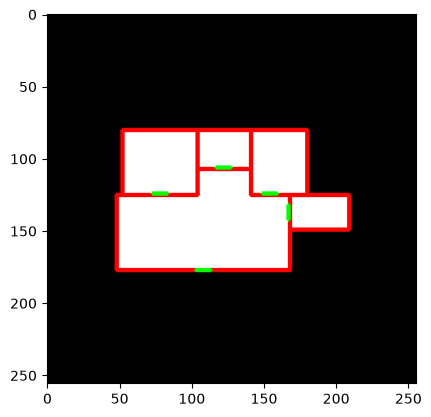

In [2]:
floorplan, outershell_mask, node_features, edge_features = next(iter(train_loader))
plt.imshow(floorplan.squeeze(0).permute(2,1,0))
print(min(floorplan.flatten()), max(floorplan.flatten()))
print(min(outershell_mask.flatten()), max(outershell_mask.flatten()))

In [4]:
train_losses = []
for epoch in range(epochs):
    model.train()
    encoder.train()
    total_loss = 0.0
    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch [{epoch + 1}/{epochs}]",
        leave=True
    )
    for floorplan, outershell_mask, node_features, edge_features in progress_bar:
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        # TODO: Multiple batches
        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )

        condition = condition.to(device)
        loss = diffusion.loss(
            floorplan,
            condition
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )
    

Epoch [1/100]: 100%|██████████| 1/1 [00:00<00:00,  1.04it/s]


Epoch [1/100] Loss: 1.090046


Epoch [2/100]: 100%|██████████| 1/1 [00:00<00:00,  2.27it/s]


Epoch [2/100] Loss: 1.085630


Epoch [3/100]: 100%|██████████| 1/1 [00:00<00:00,  2.15it/s]


Epoch [3/100] Loss: 0.999594


... (190 outputs left out)

Epoch [99/100]: 100%|██████████| 1/1 [00:00<00:00,  2.21it/s]


Epoch [99/100] Loss: 0.204323


Epoch [100/100]: 100%|██████████| 1/1 [00:00<00:00,  2.23it/s]

Epoch [100/100] Loss: 0.262849


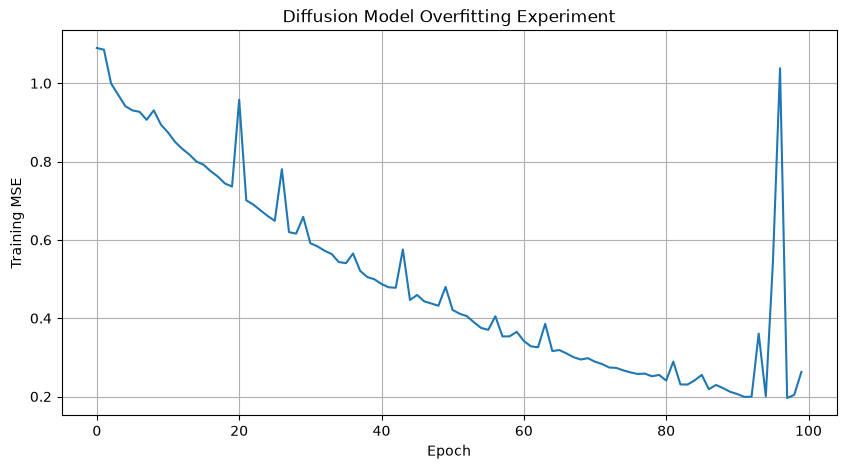

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Diffusion Model Overfitting Experiment")

plt.grid()
plt.show()

cuda:0 torch.Size([1, 512, 8, 8])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-509.22516..460.3038].


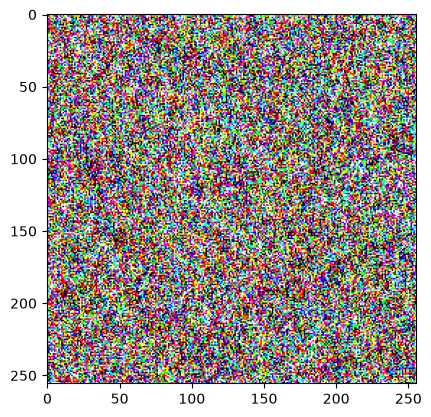

In [6]:

model.eval()
encoder.eval()

it = iter(train_loader)
for _ in range(len(train_loader)):
    floorplan, outershell_mask, node_features, edge_features = next(it)

    # Add batch dimension
    img = floorplan.unsqueeze(0).to(device)
    house_mask = outershell_mask.unsqueeze(0).to(device)
    with torch.no_grad():
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )
        print(condition.device, condition.shape)

        generated_floorplan = diffusion.sample(
            condition,
            image_size=256,
            channels=3
        )
        plt.imshow(generated_floorplan.cpu().squeeze().permute(1,2,0))
        plt.show()